# Linear Regression manual class test

##### _The purpose of this notebook is test my manual linear model class and compare it against Python's statsmodels library_

My goals are to compare:
- Regression coefficients
- Standard errors and p-values
- R-squared and adjusted R-squared
- Confidence and prediction intervals
- Variance Inflation Factor (VIF)
- Model execution time


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import time
from lm_manual_class import lm_manual

##### Simple linear model tests

For our first tests we are going to be testing on a simple linear model with one predictor 

In [2]:
# Generate some synthetic data first
rng = np.random.default_rng(42)
n = 100_000
x = rng.normal(50, 10, n)
error = rng.normal(0, 15, n)
y = 20 + 2.5 * x + error
df = pd.DataFrame({
    "x": x,
    "y": y
})
df.head()

,x,y
0,53.047171,128.998933
1,39.600159,154.863609
2,57.504512,190.705909
3,59.405647,156.084051
4,30.489648,120.244977


#### **Test #1:** Compare Summaries of both stats model and lm_manual

In [3]:
# statsmodels regression

X = sm.add_constant(df["x"])
sm_model = sm.OLS(df["y"], X).fit()
sm_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.736
Method:                 Least Squares   F-statistic:                 2.786e+05
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:41:27   Log-Likelihood:            -4.1288e+05
No. Observations:              100000   AIC:                         8.258e+05
Df Residuals:                   99998   BIC:                         8.258e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.1019      0.241     83.325      0.000      19.629      20.575
x              2.4988      0.005    527.790      0.000       2.489       2.508
==============================================================================
Omnibus:                        4.691   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.096   Jarque-Bera (JB):                4.683
Skew:                           0.015   Prob(JB):                       0.0962
Kurtosis:                       3.016   Cond. No.                         259.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [4]:
# lm_manual regression

lm_custom = lm_manual(df["x"], df["y"])

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   100000
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              20.1019        0.2412     83.3252             0            (19.6291, 20.5748)
x                       2.4988        0.0047    527.7898             0              (2.4895, 2.5081)
------------------------------------------------------------------------------------------------------------
Residual standard error: 15.0270 on 99998 degrees of freedom
R-squared: 0.7358, Adjusted R-squared: 0.7358
F-statistic: 278562.08

In [5]:
# Compare the statistics

summary_comparison = pd.DataFrame({
    "My Class": [
        lm_custom.R_squared,
        lm_custom.adjusted_r_squared,
        lm_custom.rse,
        lm_custom.f_stat,
        lm_custom.p_value
    ],
    "Statsmodels": [
        sm_model.rsquared,
        sm_model.rsquared_adj,
        np.sqrt(sm_model.mse_resid),
        sm_model.fvalue,
        sm_model.f_pvalue
    ]
}, index=[
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error",
    "F-statistic",
    "P-value"
])

summary_comparison

,My Class,Statsmodels
R-squared,0.735846,0.735846
Adjusted R-squared,0.735844,0.735844
Residual Standard Error,15.026977,15.026977
F-statistic,278562.087695,278562.087695
P-value,0.000000,0.000000


#### **Test #1** results:

Both my custom lm_manual class and the statsmodels OLS implementation produced matching regression results when fitted using the same dataset.

The coefficient estimates, standard errors, p-values, R-squared, and F-statistics were consistent between the two models.

**Conclusion:** Test #1 passed. My custom implementation produces results consistent with statsmodels for simple linear regression.

#### **Test #2:** Compare Summaries of both statsmodels and lm_manual with missing values

In [6]:
# Create a copy of previous data with some missing values

df_missing = df.copy()
df_missing.loc[rng.random(n) < 0.10, "x"] = np.nan
df_missing.loc[rng.random(n) < 0.05, "y"] = np.nan

In [7]:
# Statsmodels regression with missing values

X = sm.add_constant(df_missing["x"])
sm_model_missing = sm.OLS(df_missing["y"], X, missing="drop").fit()
sm_model_missing.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.736
Method:                 Least Squares   F-statistic:                 2.383e+05
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:41:27   Log-Likelihood:            -3.5290e+05
No. Observations:               85462   AIC:                         7.058e+05
Df Residuals:                   85460   BIC:                         7.058e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.0281      0.261     76.726      0.000      19.516      20.540
x              2.5001      0.005    488.125      0.000       2.490       2.510
==============================================================================
Omnibus:                        1.109   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.574   Jarque-Bera (JB):                1.098
Skew:                           0.005   Prob(JB):                        0.578
Kurtosis:                       3.015   Cond. No.                         259.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [8]:
# manual_lm regression with missing values

lm_custom_missing = lm_manual(df_missing["x"], df_missing["y"])

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   85462
Rows removed:        14538
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              20.0281        0.2610     76.7259             0            (19.5165, 20.5397)
x                       2.5001        0.0051    488.1253             0              (2.4901, 2.5102)
------------------------------------------------------------------------------------------------------------
Residual standard error: 15.0354 on 85460 degrees of freedom
R-squared: 0.7360, Adjusted R-squared: 0.7360
F-statistic: 238266

In [9]:
# Compare the statistics

summary_comparison_missing = pd.DataFrame({
    "My Class": [
        lm_custom_missing.R_squared,
        lm_custom_missing.adjusted_r_squared,
        lm_custom_missing.rse,
        lm_custom_missing.f_stat,
        lm_custom.p_value
    ],
    "Statsmodels": [
        sm_model_missing.rsquared,
        sm_model_missing.rsquared_adj,
        np.sqrt(sm_model_missing.mse_resid),
        sm_model_missing.fvalue,
        sm_model_missing.f_pvalue
    ]
}, index=[
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error",
    "F-statistic",
    "P-value"
])

summary_comparison_missing

,My Class,Statsmodels
R-squared,0.736012,0.736012
Adjusted R-squared,0.736009,0.736009
Residual Standard Error,15.035409,15.035409
F-statistic,238266.333923,238266.333923
P-value,0.000000,0.000000


#### **Test #2** results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression results when fitted using the dataset containing missing values.

The coefficient estimates, standard errors, p-values, R-squared, adjusted R-squared, residual standard error, and F-statistics were consistent between the two models after handling the missing observations.

**Conclusion:** Test #2 passed. My custom implementation handles missing values correctly and produces results consistent with Statsmodels for simple linear regression

#### **Test #3**: Compare prediction intervals of both statsmodels and lm_manual


In [10]:
x_new = np.array([20, 30, 40, 50, 60, 70, 80])
# My class
my_pred = lm_custom.predict(x_new)
my_ci = lm_custom.predict(x_new, interval="CONFIDENCE")
my_pi = lm_custom.predict(x_new, interval="PREDICTION")
# Statsmodels
X_new = sm.add_constant(x_new)
sm_results = sm_model.get_prediction(X_new).summary_frame(alpha=0.05)
# Comparison DataFrame
comparison = pd.DataFrame({
    "X": x_new,

    "My Prediction": np.asarray(my_pred).ravel(),
    "SM Prediction": sm_results["mean"].to_numpy(),

    "My CI Lower": my_ci["Lower Bound"].to_numpy(),
    "SM CI Lower": sm_results["mean_ci_lower"].to_numpy(),

    "My CI Upper": my_ci["Upper Bound"].to_numpy(),
    "SM CI Upper": sm_results["mean_ci_upper"].to_numpy(),

    "My PI Lower": my_pi["Lower Bound"].to_numpy(),
    "SM PI Lower": sm_results["obs_ci_lower"].to_numpy(),

    "My PI Upper": my_pi["Upper Bound"].to_numpy(),
    "SM PI Upper": sm_results["obs_ci_upper"].to_numpy()
})

comparison.round(4)

,X,My Prediction,SM Prediction,My CI Lower,SM CI Lower,My CI Upper,SM CI Upper,My PI Lower,SM PI Lower,My PI Upper,SM PI Upper
0,20,70.0774,70.0774,69.7843,69.7843,70.3706,70.3706,40.6233,40.6233,99.5316,99.5316
1,30,95.0652,95.0652,94.8579,94.8579,95.2725,95.2725,65.6118,65.6118,124.5186,124.5186
2,40,120.0530,120.0530,119.9218,119.9218,120.1841,120.1841,90.6000,90.6000,149.5059,149.5059
3,50,145.0407,145.0407,144.9476,144.9476,145.1338,145.1338,115.5879,115.5879,174.4935,174.4935
4,60,170.0285,170.0285,169.8967,169.8967,170.1602,170.1602,140.5755,140.5755,199.4814,199.4814
5,70,195.0162,195.0162,194.8082,194.8082,195.2242,195.2242,165.5628,165.5628,224.4696,224.4696
6,80,220.0040,220.0040,219.7101,219.7101,220.2979,220.2979,190.5498,190.5498,249.4581,249.4581


#### **Test #3** results:
Both my custom lm_manual class and the Statsmodels OLS implementation produced matching point predictions, confidence intervals, and prediction intervals when evaluated using the same independent variable values.

All predicted values, confidence interval bounds, and prediction interval bounds were identical to four decimal places across the seven tested observations.

**Conclusion:** Test #3 passed. My custom implementation accurately calculates point predictions, confidence intervals, and prediction intervals consistent with Statsmodels for simple linear regression.

#### **Test #4:** Compare diagnostics of both statsmodels and lm_manul

In [11]:
# My class diagnostics
my_fitted = lm_custom.fitted_y
my_resid = lm_custom.residuals
my_leverage = lm_custom.leverage
my_std_resid = lm_custom.std_residuals
my_cooks = lm_custom.cooks_distance

# Statsmodels diagnostics
sm_influence = sm_model.get_influence()

sm_fitted = sm_model.fittedvalues
sm_resid = sm_model.resid
sm_leverage = sm_influence.hat_matrix_diag
sm_std_resid = sm_influence.resid_studentized_internal
sm_cooks = sm_influence.cooks_distance[0]

diagnostics_comparison = pd.DataFrame({
    "My Fitted": np.asarray(my_fitted).ravel(),
    "SM Fitted": np.asarray(sm_fitted).ravel(),

    "My Residual": np.asarray(my_resid).ravel(),
    "SM Residual": np.asarray(sm_resid).ravel(),

    "My Leverage": np.asarray(my_leverage).ravel(),
    "SM Leverage": np.asarray(sm_leverage).ravel(),

    "My Std Residual": np.asarray(my_std_resid).ravel(),
    "SM Std Residual": np.asarray(sm_std_resid).ravel(),

    "My Cook's D": np.asarray(my_cooks).ravel(),
    "SM Cook's D": np.asarray(sm_cooks).ravel()
})

diagnostics_comparison.head(10).round(6)

,My Fitted,SM Fitted,My Residual,SM Residual,My Leverage,SM Leverage,My Std Residual,SM Std Residual,My Cook's D,SM Cook's D
0,152.654904,152.654904,-23.655971,-23.655971,0.000011,0.000011,-1.574242,-1.574242,0.000014,0.000014
1,119.053837,119.053837,35.809771,35.809771,0.000021,0.000021,2.383057,2.383057,0.000059,0.000059
2,163.792799,163.792799,26.913109,26.913109,0.000016,0.000016,1.791000,1.791000,0.000025,0.000025
3,168.543310,168.543310,-12.459259,-12.459259,0.000019,0.000019,-0.829134,-0.829134,0.000006,0.000006
4,96.288714,96.288714,23.956263,23.956263,0.000048,0.000048,1.594255,1.594255,0.000061,0.000061
5,112.502162,112.502162,-17.308559,-17.308559,0.000027,0.000027,-1.151848,-1.151848,0.000018,0.000018
6,148.235152,148.235152,-10.144934,-10.144934,0.000010,0.000010,-0.675118,-0.675118,0.000002,0.000002
7,137.138514,137.138514,0.099390,0.099390,0.000011,0.000011,0.006614,0.006614,0.000000,0.000000
8,144.620884,144.620884,-13.188555,-13.188555,0.000010,0.000010,-0.877663,-0.877663,0.000004,0.000004
9,123.725053,123.725053,9.030870,9.030870,0.000017,0.000017,0.600982,0.600982,0.000003,0.000003


#### **Test #4** Results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression diagnostic statistics when evaluated using the same dataset.

The fitted values, residuals, leverage values, standardized residuals, and Cook's distances were consistent between both models to six decimal places for the observations examined.

**Conclusion:** Test #4 passed for the displayed observations. My custom implementation accurately calculates regression diagnostics consistent with Statsmodels for simple linear regression.

#### **Test #5:** Test both plot_regression and plot_diagonistcs of lm_manual

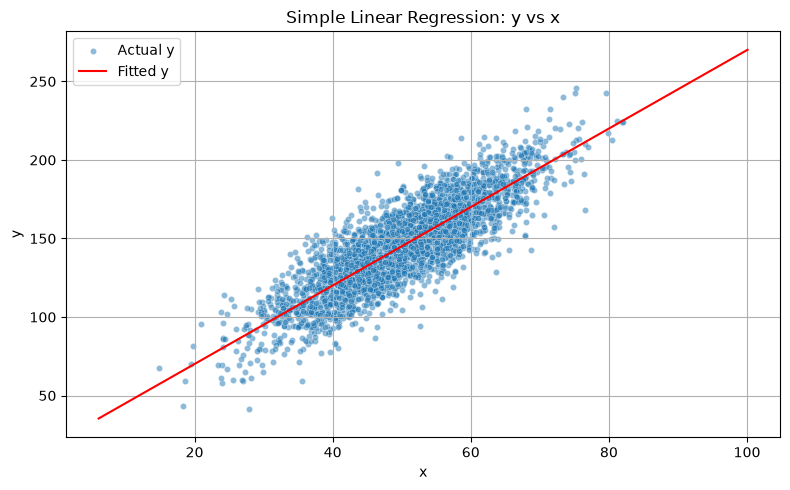

In [12]:
# Plot regression method

lm_custom.plot_regression()

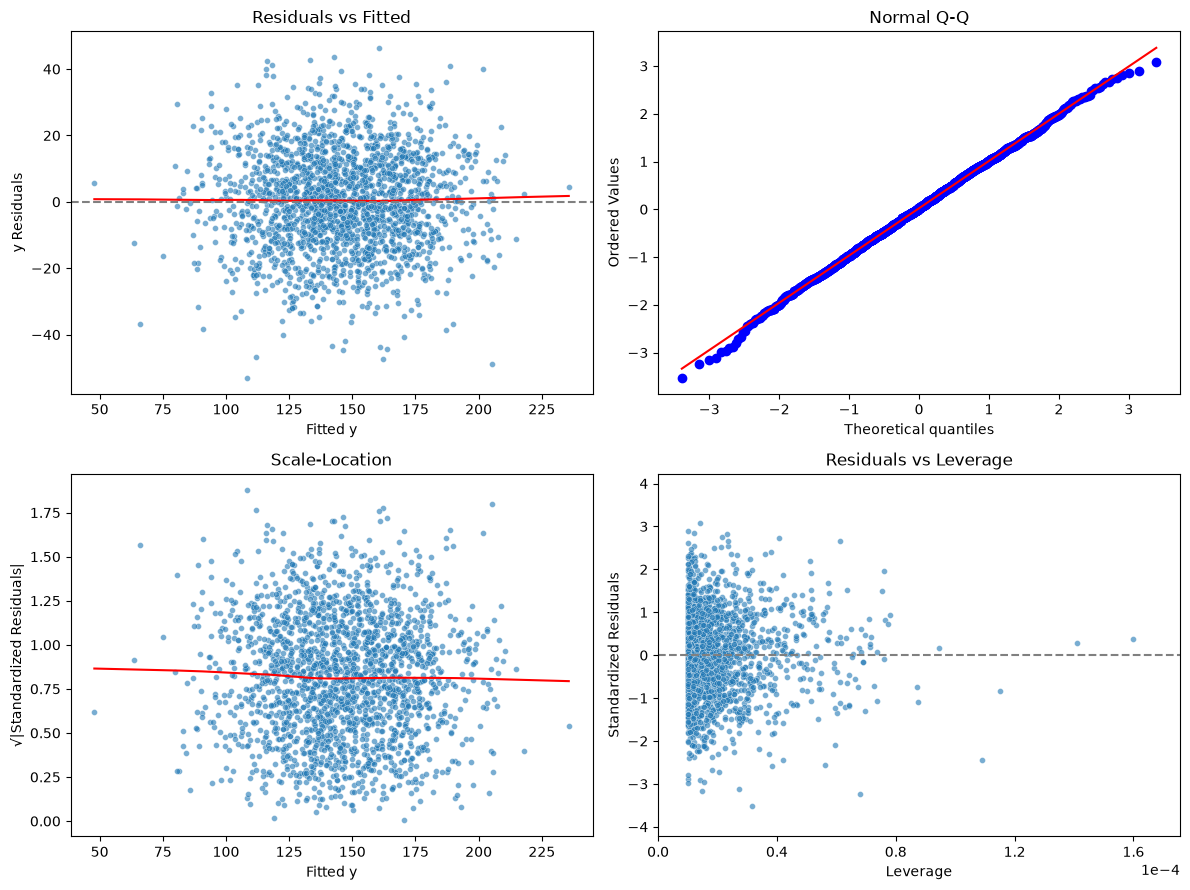

In [13]:
# Diagnostics plot

lm_custom.plot_diagnostics()

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   41
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept             146.4447       15.8913      9.2154     2.456e-11          (114.3014, 178.5879)
x                      -0.0518        0.2955     -0.1755        0.8616             (-0.6495, 0.5458)
------------------------------------------------------------------------------------------------------------
Residual standard error: 25.3973 on 39 degrees of freedom
R-squared: 0.0008, Adjusted R-squared: -0.0248
F-statistic: 0.0308 on 1 and

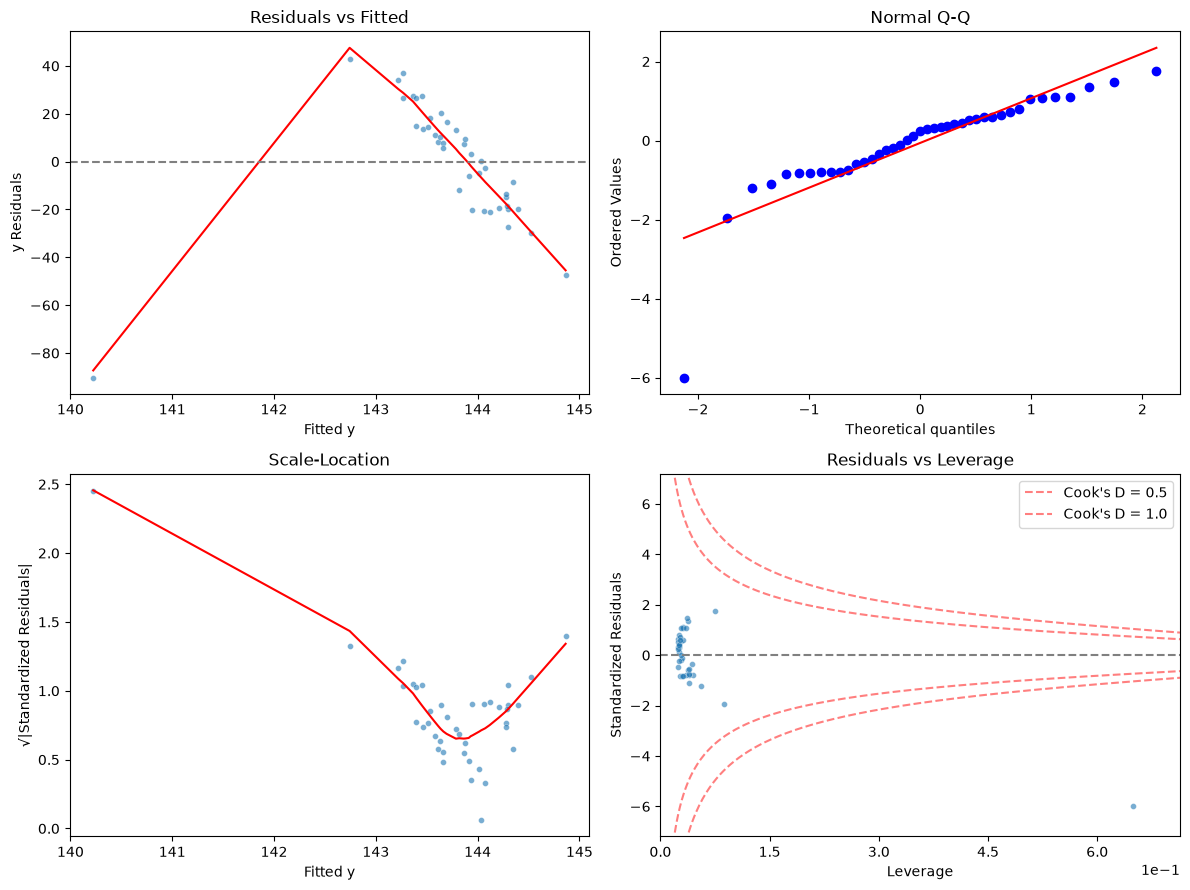

In [14]:
# Plot_Diagonostics with an infulential observation

rng = np.random.default_rng(42)
x = rng.normal(50, 10, 40)
y = 20 + 2.5 * x + rng.normal(0, 10, 40)
x = np.append(x, 120)
y = np.append(y, 50)
df_influential = pd.DataFrame({"x": x, "y": y})
test_model = lm_manual(
    df_influential["x"],
    df_influential["y"]
)
# Generate diagnostic plots
test_model.plot_diagnostics()